# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.



In [1]:
from sklearn.datasets import load_iris

# 1. Carga  del dataset
iris = load_iris(as_frame=True)
df = iris.frame


Identifica:

- **Qué representa cada instancia.**
Cada instancia representa una flor invidivual del género del que se le tomaron los datos, en este caso, del género Iris. Aquí se tomaron mediciones de sus sépalos y pétalos.

- **Número de instancias y características.**
Se tienen 150 instancias y 5 características.

- **Nombre y significado de cada característica.**
sepal length (cm): Longitud del sépalo.
sepal width (cm): Ancho del sépalo.
petal length (cm): Longitud del pétalo.
petal width (cm): Ancho del pétalo.

- **Clases y cantidad de ejemplos por clase.**
Existen 3 clases de especies de Iris con 50 ejemplos por clase

- **Dimensiones de la matriz de características y del vector de etiquetas.**
Matriz de características $X$: $(150, 4)$
Vector de etiquetas $y$: $(150,)$

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases:


Dimensiones de la matriz de características (X): (150, 4)
Dimensiones del vector de etiquetas (y): (150,)

Primeros 5 ejemplos:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Gráfico de distribucion de clases:


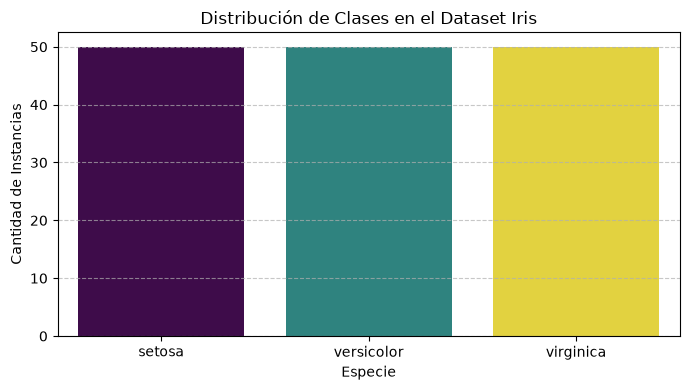

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

X, y = iris.data, iris.target
print(f"Dimensiones de la matriz de características (X): {X.shape}")
print(f"Dimensiones del vector de etiquetas (y): {y.shape}")

# Tabla con los 5 ejemplos:
print("\nPrimeros 5 ejemplos:")
display(df.head())

# Gráfico de distribución de clases
print( "Gráfico de distribucion de clases:")
plt.figure(figsize=(7, 4))
sns.countplot(x='target', data=df, palette='viridis', hue='target', legend=False)
plt.title("Distribución de Clases en el Dataset Iris")
plt.xlabel("Especie")
plt.ylabel("Cantidad de Instancias")
plt.xticks(ticks=[0, 1, 2], labels=iris.target_names)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Comparación de clasificadores

## Predicciones Iniciales

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?

Considero que serán más sensibles los modelos de regresión logística, SVM lineal y MLP. Mientras que los que no serán sensibles son árbol de decisión, Random Forest y Gradient Boosting.

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?

Considero que regresión logística multiclase y SVM lineal, ya que generan fronteras lineales. Mientras que los árboles generan fronteras ortogonales, y el MLP puede trazar fronteras más complejas.

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

Porque ningún algoritmo de aprendizaje supervisado es superior a todos los demás. El desempeño adecuado de cada algoritmo depende de los datos, el tamaño de muestra, etc.

## Preparación de los datos

Antes de entrenar cualquier modelo dividí las 150 flores en tres particiones: **entrenamiento (60%, 90 flores)**, **validación (20%, 30 flores)** y **prueba (20%, 30 flores)**. Usé `stratify` para que cada partición conserve la misma proporción de especies que el dataset completo, así ninguna especie queda sub-representada por azar.

**Corrección respecto a mi primer intento:** en la segunda división había puesto `stratify=y`, pero en ese paso ya no estaba dividiendo las 150 flores sino `X_temp` y `y_temp` (las 60 restantes). Por eso sklearn daba el error *"inconsistent numbers of samples: [60, 150]"*. Lo correcto es estratificar con `y_temp`.

Para la estandarización, el `StandardScaler` se ajusta (`fit`) **solo con entrenamiento** y después se usa esa misma media y desviación para transformar validación y prueba. Si lo ajustara con todos los datos, el modelo recibiría información de validación y prueba sin darnos cuenta (*data leakage*) y los resultados se verían mejores de lo que realmente son.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separamos 60% Train, 20% Val, 20% Test de forma estratificada
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# Corrección: aquí se estratifica con y_temp (las 60 flores restantes), no con y
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# Estandarización: el scaler aprende media y desviación SOLO con entrenamiento
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

print(f"Tamaño Train: {X_train.shape[0]} muestras")
print(f"Tamaño Validación: {X_val.shape[0]} muestras")
print(f"Tamaño Prueba: {X_test.shape[0]} muestras")

# Comprobamos que cada partición quedó balanceada
conteo = pd.DataFrame({
    "Train": y_train.value_counts().sort_index(),
    "Validación": y_val.value_counts().sort_index(),
    "Prueba": y_test.value_counts().sort_index(),
})
conteo.index = iris.target_names
display(conteo)

# Verificación rápida: en train la media debe quedar en ~0 y la desviación en ~1
print("Media en train después de escalar:     ", X_train.mean(axis=0).round(2))
print("Desviación en train después de escalar:", X_train.std(axis=0).round(2))

Tamaño Train: 90 muestras
Tamaño Validación: 30 muestras
Tamaño Prueba: 30 muestras


,Train,Validación,Prueba
setosa,30,10,10
versicolor,30,10,10
virginica,30,10,10


Media en train después de escalar:      [-0. -0. -0.  0.]
Desviación en train después de escalar: [1. 1. 1. 1.]


## Paso 1. Configuraciones iniciales

Antes de ajustar nada, definí una configuración inicial para cada modelo, en la mayoría son los valores por defecto de scikit-learn. La idea de cada uno, en pocas palabras:

| Modelo | Idea principal | Configuración inicial |
|---|---|---|
| Gaussian Naive Bayes | Supone que cada característica sigue una distribución normal dentro de cada clase y que son independientes dada la clase. Aplica el teorema de Bayes. | `var_smoothing=1e-9` |
| Regresión logística | Modelo lineal; para multiclase usa softmax para convertir los puntajes en probabilidades. | `C=1.0` |
| SVM lineal | Busca el hiperplano que separa las clases con el mayor margen posible. | `C=1.0` |
| Árbol de decisión | Hace preguntas del tipo "¿petal width ≤ umbral?" hasta llegar a una hoja. | `max_depth=None` |
| Random Forest | Muchos árboles entrenados con muestras bootstrap y subconjuntos de características; decide por votación. | `n_estimators=100` |
| Gradient Boosting | Árboles pequeños construidos en secuencia, cada uno corrige los errores de los anteriores. | `n_estimators=100, learning_rate=0.1, max_depth=3` |
| MLP | Red neuronal con una capa oculta y activación ReLU; la salida usa softmax. | `hidden_layer_sizes=(10,), alpha=1e-4` |

Todos los modelos reciben las características estandarizadas, como pide el enunciado.

In [16]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

# Configuraciones iniciales de los 7 clasificadores
modelos_iniciales = {
    "Gaussian Naive Bayes": GaussianNB(var_smoothing=1e-9),
    "Regresión logística": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "SVM lineal": LinearSVC(C=1.0, max_iter=10000, random_state=42),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=None, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(10,), alpha=1e-4, max_iter=2000, random_state=42
    ),
}


def evaluar(modelo, X_eval, y_eval):
    # Devuelve accuracy y F1 macro de un modelo ya entrenado
    pred = modelo.predict(X_eval)
    return accuracy_score(y_eval, pred), f1_score(y_eval, pred, average="macro")

## Pasos 2 y 3. Entrenamiento y comparación en validación

Cada modelo se entrena **solo con la partición de entrenamiento** y se evalúa en **validación** con dos métricas:

- **Accuracy:** proporción de flores bien clasificadas.
- **F1 macro:** calcula el F1 de cada especie por separado y luego los promedia, dándole el mismo peso a las tres especies.

In [5]:
filas = []
for nombre, modelo in modelos_iniciales.items():
    modelo.fit(X_train, y_train)
    acc, f1 = evaluar(modelo, X_val, y_val)
    filas.append({"Modelo": nombre, "Accuracy validación": acc, "F1 macro validación": f1})

resultados_val_iniciales = pd.DataFrame(filas)
display(resultados_val_iniciales.round(3))

,Modelo,Accuracy validación,F1 macro validación
0,Gaussian Naive Bayes,0.933,0.933
1,Regresión logística,0.933,0.933
2,SVM lineal,0.933,0.933
3,Árbol de decisión,0.933,0.933
4,Random Forest,0.933,0.933
5,Gradient Boosting,0.933,0.933
6,MLP,0.967,0.967


## Paso 4. Ajustes limitados usando solamente validación

Para cada modelo probé una búsqueda pequeña de hiperparámetros (2 a 4 valores por hiperparámetro), enfocada en los que controlan la complejidad o la regularización:

- **Naive Bayes:** `var_smoothing` (suavizado de las varianzas).
- **Regresión logística y SVM lineal:** `C` (un `C` pequeño regulariza más, es decir, un modelo más simple).
- **Árbol de decisión:** `max_depth` (profundidad máxima).
- **Random Forest:** `max_depth` y `n_estimators`.
- **Gradient Boosting:** `learning_rate`, `max_depth` y `n_estimators`.
- **MLP:** tamaño de la capa oculta y `alpha` (regularización L2).

**Criterio de selección:** me quedo con la configuración con mayor **F1 macro en validación**; si hay empate, desempata el accuracy, y si sigue empatado escojo la que aparece primero en la búsqueda. En cada lista puse primero las opciones más simples (más suavizado o regularización, menor `C`, menor profundidad, menos árboles y menos neuronas), para que en caso de empate se elija el modelo menos complejo. Muestro las métricas con 4 decimales porque con solo 30 flores de validación varias configuraciones quedan casi empatadas.

La partición de prueba **no se usa** en este paso.

In [6]:
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid

grids = {
    "Gaussian Naive Bayes": {"var_smoothing": [1e-5, 1e-7, 1e-9]},
    "Regresión logística": {"C": [0.1, 1.0, 10.0]},
    "SVM lineal": {"C": [0.1, 1.0, 10.0]},
    "Árbol de decisión": {"max_depth": [2, 3, 4, None]},
    "Random Forest": {"max_depth": [2, 3, None], "n_estimators": [50, 100]},
    "Gradient Boosting": {
        "learning_rate": [0.05, 0.1], "max_depth": [1, 2, 3], "n_estimators": [50, 100]
    },
    "MLP": {"alpha": [1e-2, 1e-4], "hidden_layer_sizes": [(5,), (10,), (20,)]},
}

busqueda = []   # todas las combinaciones probadas
mejores = {}    # mejor configuración de cada modelo

for nombre, grid in grids.items():
    candidatos = []
    for orden, params in enumerate(ParameterGrid(grid)):
        modelo = clone(modelos_iniciales[nombre]).set_params(**params)
        modelo.fit(X_train, y_train)
        acc, f1 = evaluar(modelo, X_val, y_val)
        candidatos.append({
            "Modelo": nombre, "Hiperparámetros": params,
            "Accuracy validación": acc, "F1 macro validación": f1,
            "orden": orden, "estimador": modelo,
        })
    busqueda.extend(candidatos)
    # Mayor F1 macro -> mayor accuracy -> el que aparece primero
    mejores[nombre] = max(
        candidatos,
        key=lambda c: (c["F1 macro validación"], c["Accuracy validación"], -c["orden"]),
    )

tabla_busqueda = pd.DataFrame(busqueda).drop(columns=["orden", "estimador"])
tabla_busqueda["Hiperparámetros"] = tabla_busqueda["Hiperparámetros"].astype(str)
print(f"Se probaron {len(tabla_busqueda)} configuraciones en total\n")
with pd.option_context("display.max_rows", 100, "display.max_colwidth", None):
    display(tabla_busqueda.round(4))

Se probaron 37 configuraciones en total



,Modelo,Hiperparámetros,Accuracy validación,F1 macro validación
0,Gaussian Naive Bayes,{'var_smoothing': 1e-05},0.9333,0.9333
1,Gaussian Naive Bayes,{'var_smoothing': 1e-07},0.9333,0.9333
2,Gaussian Naive Bayes,{'var_smoothing': 1e-09},0.9333,0.9333
3,Regresión logística,{'C': 0.1},0.8667,0.8653
4,Regresión logística,{'C': 1.0},0.9333,0.9333
5,Regresión logística,{'C': 10.0},0.9333,0.9333
6,SVM lineal,{'C': 0.1},0.8333,0.8295
7,SVM lineal,{'C': 1.0},0.9333,0.9327
8,SVM lineal,{'C': 10.0},0.9333,0.9333
9,Árbol de decisión,{'max_depth': 2},0.9000,0.8997


## Paso 5. Configuraciones congeladas

Estas son las configuraciones elegidas en validación. A partir de aquí **quedan congeladas**: no se vuelven a cambiar, aunque los resultados de prueba no me gusten. La tabla también compara el F1 macro de la configuración inicial con el de la elegida para ver si el ajuste sirvió de algo.

In [7]:
def formatear(params):
    return ", ".join(f"{k}={v}" for k, v in params.items())


modelos_finales = {nombre: c["estimador"] for nombre, c in mejores.items()}

tabla_congelada = pd.DataFrame([{
    "Modelo": nombre,
    "Hiperparámetros congelados": formatear(c["Hiperparámetros"]),
    "F1 macro val. (inicial)": resultados_val_iniciales.set_index("Modelo").loc[nombre, "F1 macro validación"],
    "Accuracy val. (congelado)": c["Accuracy validación"],
    "F1 macro val. (congelado)": c["F1 macro validación"],
} for nombre, c in mejores.items()])

with pd.option_context("display.max_colwidth", None):
    display(tabla_congelada.round(4))

,Modelo,Hiperparámetros congelados,F1 macro val. (inicial),Accuracy val. (congelado),F1 macro val. (congelado)
0,Gaussian Naive Bayes,var_smoothing=1e-05,0.9333,0.9333,0.9333
1,Regresión logística,C=1.0,0.9333,0.9333,0.9333
2,SVM lineal,C=10.0,0.9327,0.9333,0.9333
3,Árbol de decisión,max_depth=3,0.9333,0.9667,0.9666
4,Random Forest,"max_depth=2, n_estimators=50",0.9333,0.9333,0.9333
5,Gradient Boosting,"learning_rate=0.05, max_depth=1, n_estimators=50",0.9333,0.9667,0.9666
6,MLP,"alpha=0.01, hidden_layer_sizes=(5,)",0.9666,0.9667,0.9666


## Resultados

### Paso 6. Evaluación final en prueba

Ahora sí, cada modelo congelado (entrenado con las 90 flores de entrenamiento) clasifica las 30 flores de prueba, que no se usaron en ningún paso anterior. Esta tabla solo **describe** el desempeño final; no se usa para hacer otra ronda de ajustes.

,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,StandardScaler,var_smoothing=1e-05,0.933,0.933
1,Regresión logística,StandardScaler,C=1.0,0.933,0.933
2,SVM lineal,StandardScaler,C=10.0,0.933,0.933
3,Árbol de decisión,StandardScaler,max_depth=3,1.000,1.000
4,Random Forest,StandardScaler,"max_depth=2, n_estimators=50",0.933,0.933
5,Gradient Boosting,StandardScaler,"learning_rate=0.05, max_depth=1, n_estimators=50",1.000,1.000
6,MLP,StandardScaler,"alpha=0.01, hidden_layer_sizes=(5,)",1.000,1.000


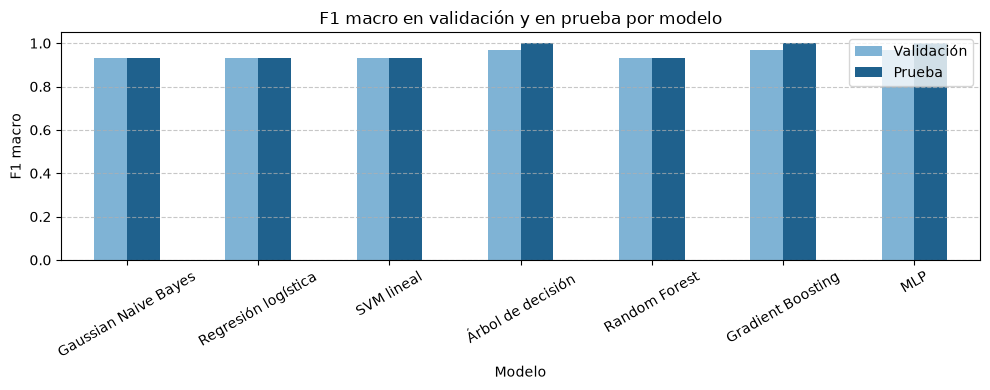

In [8]:
filas_prueba = []
predicciones_prueba = {}

for nombre, modelo in modelos_finales.items():
    pred = modelo.predict(X_test)
    predicciones_prueba[nombre] = pred
    filas_prueba.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": formatear(mejores[nombre]["Hiperparámetros"]),
        "Accuracy de prueba": accuracy_score(y_test, pred),
        "F1 macro de prueba": f1_score(y_test, pred, average="macro"),
    })

resultados_prueba = pd.DataFrame(filas_prueba)
with pd.option_context("display.max_colwidth", None):
    display(resultados_prueba.round(3))

# Gráfico comparativo: validación (congelado) vs. prueba
comparacion = pd.DataFrame({
    "Validación": tabla_congelada.set_index("Modelo")["F1 macro val. (congelado)"],
    "Prueba": resultados_prueba.set_index("Modelo")["F1 macro de prueba"],
})
ax = comparacion.plot(kind="bar", figsize=(10, 4), color=["#7fb3d5", "#1f618d"], rot=30)
ax.set_ylabel("F1 macro")
ax.set_ylim(0, 1.05)
ax.set_title("F1 macro en validación y en prueba por modelo")
ax.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### Matrices de confusión (Naive Bayes, SVM lineal y MLP)

En cada matriz las filas son la especie real y las columnas la especie predicha. La diagonal son los aciertos y lo que queda fuera de la diagonal son las confusiones.

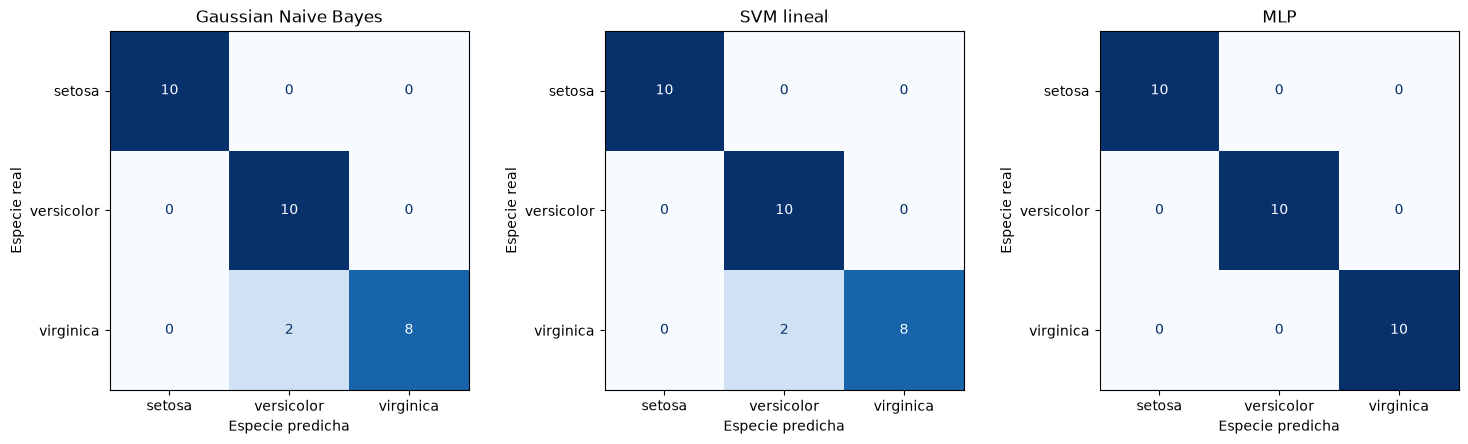

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, nombre in zip(axes, ["Gaussian Naive Bayes", "SVM lineal", "MLP"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicciones_prueba[nombre],
        display_labels=iris.target_names, cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(nombre)
    ax.set_xlabel("Especie predicha")
    ax.set_ylabel("Especie real")
plt.tight_layout()
plt.show()

### Análisis de dos errores de clasificación

Primero junté todos los errores que cometieron los modelos en prueba para ver qué flores fallan y cuántos modelos se equivocan en cada una. Luego elegí las dos flores en las que más modelos fallaron y comparé sus medidas con el promedio de cada especie en entrenamiento.

Flores de prueba mal clasificadas por al menos un modelo:


,Índice flor,Especie real,Modelos que fallan,Predicha como
0,133,virginica,4,versicolor
1,134,virginica,4,versicolor


Medidas originales (cm) de las dos flores seleccionadas:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Especie real
133,6.3,2.8,5.1,1.5,virginica
134,6.1,2.6,5.6,1.4,virginica


Promedio de cada especie en entrenamiento (cm):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,4.99,3.44,1.49,0.24
versicolor,5.97,2.74,4.27,1.31
virginica,6.65,3.02,5.62,2.06


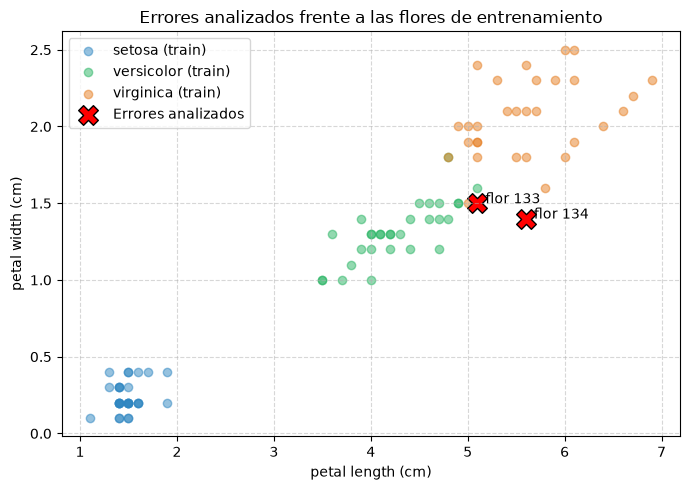

In [10]:
y_test_arr = y_test.to_numpy()

# Todos los errores de prueba: qué flor, qué modelo se equivocó y qué predijo
errores = []
for nombre, pred in predicciones_prueba.items():
    for pos in np.flatnonzero(pred != y_test_arr):
        errores.append({
            "Índice flor": X_test_raw.index[pos],
            "Modelo": nombre,
            "Especie real": iris.target_names[y_test_arr[pos]],
            "Especie predicha": iris.target_names[pred[pos]],
        })
errores = pd.DataFrame(errores)

resumen_errores = (
    errores.groupby(["Índice flor", "Especie real"])
    .agg(**{
        "Modelos que fallan": ("Modelo", "count"),
        "Predicha como": ("Especie predicha", lambda s: ", ".join(sorted(set(s)))),
    })
    .reset_index()
    .sort_values("Modelos que fallan", ascending=False)
)
print("Flores de prueba mal clasificadas por al menos un modelo:")
display(resumen_errores)

# Seleccionamos las dos flores en las que más modelos fallaron
seleccion = resumen_errores["Índice flor"].head(2).tolist()
print("Medidas originales (cm) de las dos flores seleccionadas:")
display(X_test_raw.loc[seleccion].assign(
    **{"Especie real": [iris.target_names[y.loc[i]] for i in seleccion]}
))

# Promedio de cada especie en entrenamiento, como referencia
medias = X_train_raw.groupby(y_train).mean()
medias.index = iris.target_names
print("Promedio de cada especie en entrenamiento (cm):")
display(medias.round(2))

# Gráfico: las dos flores sobre las medidas de pétalo de entrenamiento
fig, ax = plt.subplots(figsize=(7, 5))
for clase, color in zip(range(3), ["#2e86c1", "#28b463", "#e67e22"]):
    puntos = X_train_raw[y_train == clase]
    ax.scatter(puntos["petal length (cm)"], puntos["petal width (cm)"],
               color=color, alpha=0.5, label=f"{iris.target_names[clase]} (train)")
ax.scatter(X_test_raw.loc[seleccion, "petal length (cm)"],
           X_test_raw.loc[seleccion, "petal width (cm)"],
           color="red", marker="X", s=200, edgecolor="black", label="Errores analizados")
for i in seleccion:
    ax.annotate(f"  flor {i}", (X_test_raw.loc[i, "petal length (cm)"],
                                X_test_raw.loc[i, "petal width (cm)"]))
ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title("Errores analizados frente a las flores de entrenamiento")
ax.legend()
ax.grid(linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Interpretación

### 1. ¿Cuál fue el modelo con el mejor desempeño?
En la fase de validación, tras hacer los ajustes de hiperparámetros, tres modelos empataron en el primer lugar con una exactitud de 0.967 y F1 macro de 0.967: el **Árbol de decisión**, **Gradient Boosting** y el **MLP**.

Al evaluar finalmente en el conjunto de prueba con las 30 flores que nunca antes habían visto, estos mismos tres modelos (**Árbol de decisión**, **Gradient Boosting** y **MLP**) obtuvieron un rendimiento con un **Accuracy de 1.000 y un F1 macro de 1.000** (acertaron las 30 flores). Los otros cuatro modelos (Gaussian Naive Bayes, Regresión logística, SVM lineal y Random Forest) quedaron empatados en segundo lugar con **0.933** en ambas métricas, cometiendo exactamente 2 errores de 30 posibles. Por lo tanto, en este experimento no hay un único ganador absoluto, sino un triple empate.

### 2. ¿Cuál fue el modelo más sencillo de programar?
Para mí, el modelo más sencillo de programar y configurar fue **Gaussian Naive Bayes**. Es un algoritmo basado directamente en probabilidades y en el teorema de Bayes que asume que las características son independientes entre sí. No requiere procesos de optimización iterativa complejos (como descenso de gradiente) ni requiere buscar muchos hiperparámetros (prácticamente usamos los valores estándar y solo probamos el suavizado `var_smoothing`).

### 3. ¿Accuracy y F1 macro cuentan la misma historia?
En este experimento en específico sí cuentan la misma historia: los tres mejores modelos tienen 1.000 tanto en Accuracy como en F1 macro, y los otros cuatro tienen 0.933 en ambas métricas.

Esto ocurrió porque nuestro conjunto de prueba está perfectamente balanceado (contiene exactamente 10 flores de cada especie: setosa, versicolor y virginica), y los pocos errores que hubo afectaron a las clases de manera pareja. 

### 4. ¿Cuál es la diferencia entre las métricas macro y micro?
La diferencia radica en el nivel en el que se hace el promedio:
- **Macro:** calcula la métrica (como precisión, recall o F1) de forma independiente para cada clase y luego saca un promedio aritmético simple entre ellas. Esto significa que todas las clases tienen exactamente el mismo peso en el resultado final, sin importar si una clase tiene 100 flores y otra solo tiene 5.
- **Micro:** agrega primero todos los aciertos y fallos (verdaderos positivos, falsos positivos y falsos negativos) de todas las clases a nivel global y después calcula la métrica global sobre esos totales. En la clasificación multiclase donde cada flor solo pertenece a una especie, **F1 micro coincide exactamente con el Accuracy**.

### 5. ¿Qué aporta el MLP frente a un modelo lineal?
Un modelo lineal (como la Regresión Logística o la SVM lineal) busca separar las clases utilizando hiperplanos rectos. Si las clases no son linealmente separables en el espacio de características, un modelo lineal siempre va a tener problemas en las zonas de solapamiento.

El **MLP** aporta una o más capas ocultas con funciones de activación no lineales (como ReLU). Esta estructura le permite transformar las características y aprender fronteras de decisión curvas y más complejas. En nuestro experimento de prueba esto se vio en la práctica: mientras que la Regresión Logística y la SVM lineal se equivocaron en dos flores limítrofes, el MLP logró trazar una separación adecuada y obtuvo una exactitud del 100% (1.000). Sin embargo, al tener un conjunto de prueba pequeño (solo 30 flores), esta mayor complejidad no garantiza que el MLP siempre vaya a ser mejor en cualquier otro dataset.

### Análisis de dos errores de clasificación

**Identificación de las flores analizadas:**
Al revisar los fallos cometidos en el conjunto de prueba (celda anterior), encontramos que solo dos flores causaron todos los errores de los modelos: la **flor 133** y la **flor 134**. Ambas son en realidad de la especie **virginica**, pero cuatro modelos (**Gaussian Naive Bayes, Regresión logística, SVM lineal y Random Forest**) las clasificaron erróneamente como **versicolor**.

### Alcance de la comparación
- Todos los modelos evaluados utilizaron las características estandarizadas con `StandardScaler`, lo que permitió una comparación homogénea bajo las mismas condiciones.
- Se respetó de forma rigurosa la metodología experimental: el conjunto de validación sirvió exclusivamente para seleccionar y congelar las mejores configuraciones, y el conjunto de prueba se reservó como una evaluación final objetiva, sin hacer nuevos ajustes a posteriori.


# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga del dataset Diabetes incluido en scikit-learn con `scaled=False` para trabajar con las variables antes del escalado automático que aplica la librería.

### Identificación y descripción de variables

- **Objetivo numérico (`target`):** Representa una medida cuantitativa continua del avance o progresión de la enfermedad en cada paciente un año después de las mediciones iniciales. En la documentación no se especifica una unidad clínica concreta, por lo que las predicciones y los errores se interpretan en las unidades de esta escala.
- **Variables contenidas:** Contiene 10 características clínicas por paciente:
  - `age`: Edad del paciente.
  - `sex`: Sexo (codificado numéricamente como 1.0 y 2.0).
  - `bmi`: Índice de masa corporal.
  - `bp`: Presión arterial media.
  - `s1` a `s6`: Seis mediciones de suero sanguíneo (colesterol total, LDL, HDL, relación colesterol/HDL, logaritmo de triglicéridos y glucosa).
- **Transformaciones previas comprobadas:** Al revisar la documentación (`DESCR`), por defecto `load_diabetes` centra todas las características y las divide por su desviación estándar por la raíz de $n$. Al usar `scaled=False` evitamos ese pre-escalamiento global y obtenemos los datos sin estandarizar. Sin embargo, variables como `sex` están codificadas y `s5` ya viene en escala logarítmica, por lo que no debemos interpretar todos los valores directamente como mediciones físicas brutas.
- **Número de instancias y características:** El dataset cuenta con 442 instancias (pacientes) y 10 características predictoras.


Dimensiones de X (características): (442, 10)
Dimensiones de y (objetivo): (442,)

Primeras 5 filas del dataset:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


C:\Users\brand\AppData\Local\Temp\ipykernel_26476\671646814.py:26: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax2.boxplot(y_diabetes, vert=False, patch_artist=True, boxprops=dict(facecolor="#aed6f1"))


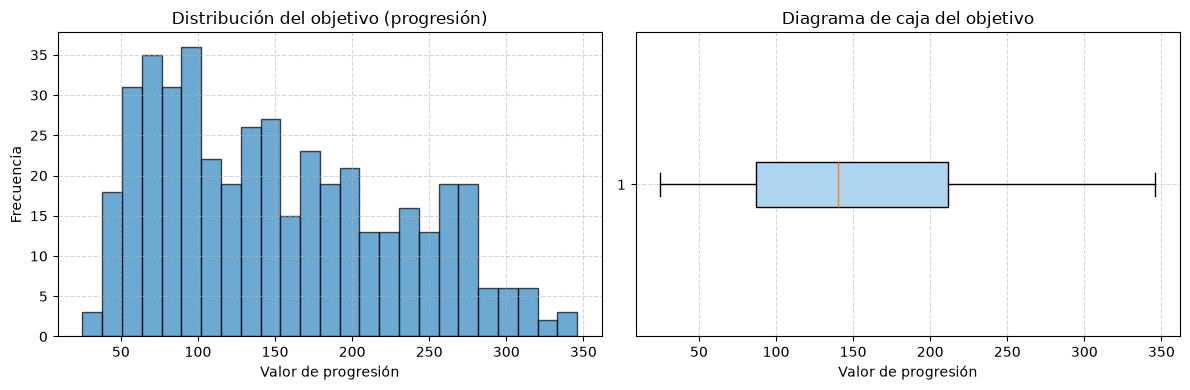

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

# Carga del dataset sin escalado automático previo
diabetes = load_diabetes(as_frame=True, scaled=False)
X_diabetes = diabetes.data
y_diabetes = diabetes.target

print(f"Dimensiones de X (características): {X_diabetes.shape}")
print(f"Dimensiones de y (objetivo): {y_diabetes.shape}")

# Primeros 5 ejemplos
print("\nPrimeras 5 filas del dataset:")
display(diabetes.frame.head(5))

# Distribución del objetivo de progresión
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(y_diabetes, bins=25, color="#2e86c1", edgecolor="black", alpha=0.7)
ax1.set_title("Distribución del objetivo (progresión)")
ax1.set_xlabel("Valor de progresión")
ax1.set_ylabel("Frecuencia")
ax1.grid(linestyle="--", alpha=0.5)

ax2.boxplot(y_diabetes, vert=False, patch_artist=True, boxprops=dict(facecolor="#aed6f1"))
ax2.set_title("Diagrama de caja del objetivo")
ax2.set_xlabel("Valor de progresión")
ax2.grid(linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## Predicción inicial y Protocolo experimental

### Predicción inicial
**¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.**

No espero que un modelo más flexible tenga siempre un menor error en datos nuevos. Un modelo con mucha flexibilidad tiene una gran capacidad para memorizar el ruido o detalles específicos de los datos de entrenamiento (sobreajuste), lo que suele provocar errores grandes cuando se enfrenta a pacientes nuevos que no ha visto. En cambio, modelos más sencillos o restringidos suelen generalizar de forma más estable en problemas con pocas muestras relativas al número de variables.

---

### Protocolo experimental

- **Separación de datos:** Dividí los 442 pacientes en tres conjuntos:
  - **Entrenamiento (60%, 265 pacientes):** Para ajustar los parámetros de cada modelo.
  - **Validación (20%, 88 pacientes):** Para comparar y elegir hiperparámetros.
  - **Prueba (20%, 89 pacientes):** Reservado estrictamente para la evaluación final congelada.
  - Usé `random_state=42`. En regresión el objetivo es continuo, por lo que no se utiliza estratificación (`stratify`).
- **Criterio de selección:** El criterio principal para elegir la mejor configuración en validación es el menor **RMSE** (Raíz del Error Cuadrático Medio), ya que eleva los residuos al cuadrado y penaliza con mayor rigor los errores grandes. En caso de empate se usa el **MAE** (Error Absoluto Medio). También calculamos $R^2$ para medir la proporción de varianza explicada.
- **Modelo de referencia constante:** Definí como línea base un `DummyRegressor(strategy="mean")`, que predice para todos los pacientes la media del objetivo obtenida en los datos de desarrollo. Si un modelo no supera a esta referencia, no está aprendiendo información predictiva útil.


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# División: 60% Train, 20% Val, 20% Test
X_reg_train, X_reg_temp, y_reg_train, y_reg_temp = train_test_split(
    X_diabetes, y_diabetes, test_size=0.40, random_state=42
)
X_reg_val, X_reg_test, y_reg_val, y_reg_test = train_test_split(
    X_reg_temp, y_reg_temp, test_size=0.50, random_state=42
)

print(f"Pacientes en entrenamiento: {len(X_reg_train)}")
print(f"Pacientes en validación:    {len(X_reg_val)}")
print(f"Pacientes en prueba:        {len(X_reg_test)}")

# Función para calcular las tres métricas clave
def evaluar_regresion(y_real, y_pred):
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": root_mean_squared_error(y_real, y_pred),
        "R2": r2_score(y_real, y_pred)
    }


Pacientes en entrenamiento: 265
Pacientes en validación:    88
Pacientes en prueba:        89


## Paso 1. Configuraciones iniciales

Definí ocho regresores con configuraciones iniciales estándar. Para evitar fugas de información, el escalamiento de variables se empaquetó dentro de un `Pipeline` de scikit-learn:

- **Modelos lineales y basados en distancias (Regresión lineal, Ridge, Lasso, kNN y MLP):** Requieren estandarizar las entradas con `StandardScaler`, ya que la escala de los predictores influye directamente en las distancias euclidianas y en las penalizaciones de los coeficientes.
- **Modelos basados en árboles (Árbol de regresión, Random Forest y Gradient Boosting):** No requieren escalamiento, ya que evalúan umbrales de división individuales para cada variable.
- **MLP de regresión:** Además de estandarizar las entradas, utilicé `TransformedTargetRegressor` con `StandardScaler` en el objetivo numérico. Esto ayuda a que el algoritmo de optimización (Adam) converja de forma estable y las predicciones se devuelvan automáticamente a la escala original del objetivo.


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

regresores_iniciales = {
    "Regresión lineal": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Ridge(alpha=1.0, random_state=42))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Lasso(alpha=1.0, random_state=42))
    ]),
    "kNN": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", KNeighborsRegressor(n_neighbors=5, weights="uniform"))
    ]),
    "Árbol de regresión": DecisionTreeRegressor(
        max_depth=None, min_samples_leaf=5, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=None, min_samples_leaf=5, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.1, max_depth=2, random_state=42
    ),
    "MLP": TransformedTargetRegressor(
        regressor=Pipeline([
            ("scaler", StandardScaler()),
            ("reg", MLPRegressor(hidden_layer_sizes=(16,), alpha=0.01, solver="adam",
                                max_iter=3000, early_stopping=True, n_iter_no_change=30, random_state=42))
        ]),
        transformer=StandardScaler()
    )
}


## Pasos 2 y 3. Entrenamiento y evaluación inicial en validación

Cada modelo inicial se entrena exclusivamente con el conjunto de entrenamiento (265 pacientes) y se evalúa en el conjunto de validación (88 pacientes).


In [20]:
filas_val_inicial = []

for nombre, modelo in regresores_iniciales.items():
    modelo.fit(X_reg_train, y_reg_train)
    m = evaluar_regresion(y_reg_val, modelo.predict(X_reg_val))
    filas_val_inicial.append({
        "Modelo": nombre,
        "RMSE validación": m["RMSE"],
        "MAE validación": m["MAE"],
        "R2 validación": m["R2"]
    })

resultados_val_iniciales = pd.DataFrame(filas_val_inicial)
display(resultados_val_iniciales.round(3))


,Modelo,RMSE validación,MAE validación,R2 validación
0,Regresión lineal,49.150,38.221,0.581
1,Ridge,49.203,38.294,0.580
2,Lasso,49.525,38.685,0.575
3,kNN,57.707,45.452,0.422
4,Árbol de regresión,66.407,52.704,0.235
5,Random Forest,53.478,42.315,0.504
6,Gradient Boosting,52.404,41.756,0.524
7,MLP,52.590,40.262,0.520


## Paso 4. Ajustes limitados usando solamente validación

Para cada modelo probé una búsqueda pequeña de hiperparámetros (máximo 4 a 8 combinaciones) enfocada en los parámetros que controlan la complejidad o la regularización:

- **Ridge:** `alpha` ([0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]), controla la penalización L2.
- **Lasso:** `alpha` ([0.001, 0.01, 0.1, 1.0, 10.0, 100.0]), controla la penalización L1 y la dispersión.
- **kNN:** `n_neighbors` ([3, 5, 11, 21]) y `weights` (uniform vs distance).
- **Árbol de regresión:** `max_depth` ([2, 3, 5, None]) y `min_samples_leaf` ([5, 15]).
- **Random Forest:** `n_estimators` ([100, 200]), `max_depth` ([3, None]) y `min_samples_leaf` ([1, 5]).
- **Gradient Boosting:** `n_estimators` ([50, 100]), `learning_rate` ([0.05, 0.1]) y `max_depth` ([1, 2]).
- **MLP:** `hidden_layer_sizes` ([(8,), (16,), (32,)]) y regularización L2 `alpha` ([0.001, 0.01, 0.1]).


In [21]:
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid

grids_regresion = {
    "Regresión lineal": {},
    "Ridge": {"reg__alpha": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]},
    "Lasso": {"reg__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]},
    "kNN": {"reg__n_neighbors": [3, 5, 11, 21], "reg__weights": ["uniform", "distance"]},
    "Árbol de regresión": {"max_depth": [2, 3, 5, None], "min_samples_leaf": [5, 15]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [3, None], "min_samples_leaf": [1, 5]},
    "Gradient Boosting": {"n_estimators": [50, 100], "learning_rate": [0.05, 0.1], "max_depth": [1, 2]},
    "MLP": {"regressor__reg__hidden_layer_sizes": [(8,), (16,), (32,)], "regressor__reg__alpha": [0.001, 0.01, 0.1]}
}

mejores_regresores = {}
historial_busqueda = {}

for nombre, grid in grids_regresion.items():
    modelo_base = regresores_iniciales[nombre]
    if not grid:
        rmse_ini = resultados_val_iniciales.loc[resultados_val_iniciales["Modelo"] == nombre, "RMSE validación"].values[0]
        mae_ini = resultados_val_iniciales.loc[resultados_val_iniciales["Modelo"] == nombre, "MAE validación"].values[0]
        r2_ini = resultados_val_iniciales.loc[resultados_val_iniciales["Modelo"] == nombre, "R2 validación"].values[0]
        mejores_regresores[nombre] = {
            "modelo": modelo_base,
            "params": {},
            "RMSE_val": rmse_ini,
            "MAE_val": mae_ini,
            "R2_val": r2_ini
        }
        continue

    candidatos = []
    for params in ParameterGrid(grid):
        c = clone(modelo_base)
        c.set_params(**params)
        c.fit(X_reg_train, y_reg_train)
        pred_val = c.predict(X_reg_val)
        pred_tr = c.predict(X_reg_train)
        m_val = evaluar_regresion(y_reg_val, pred_val)
        m_tr = evaluar_regresion(y_reg_train, pred_tr)
        candidatos.append({
            "modelo": c,
            "params": params,
            "RMSE_val": m_val["RMSE"],
            "MAE_val": m_val["MAE"],
            "R2_val": m_val["R2"],
            "RMSE_train": m_tr["RMSE"]
        })
    historial_busqueda[nombre] = candidatos
    # Seleccionamos la mejor configuración por menor RMSE en validación
    mejor = min(candidatos, key=lambda x: (x["RMSE_val"], x["MAE_val"]))
    mejores_regresores[nombre] = mejor


## Paso 5. Configuraciones congeladas

Estas son las configuraciones seleccionadas a partir del desempeño en validación. A partir de aquí quedan congeladas para la prueba final. Comparamos el RMSE de la configuración inicial frente al de la elegida para comprobar si el ajuste produjo mejoras:


In [22]:
def formatear_params(params_dict):
    limpio = {k.split("__")[-1]: v for k, v in params_dict.items()}
    return ", ".join(f"{k}={v}" for k, v in limpio.items()) if limpio else "valores por defecto"

filas_congeladas = []
for nombre, d in mejores_regresores.items():
    rmse_ini = resultados_val_iniciales.loc[resultados_val_iniciales["Modelo"] == nombre, "RMSE validación"].values[0]
    filas_congeladas.append({
        "Modelo": nombre,
        "Hiperparámetros congelados": formatear_params(d["params"]),
        "RMSE val (inicial)": rmse_ini,
        "RMSE val (congelado)": d["RMSE_val"],
        "MAE val (congelado)": d["MAE_val"],
        "R2 val (congelado)": d["R2_val"]
    })

tabla_congelada = pd.DataFrame(filas_congeladas)
display(tabla_congelada.round(3))


,Modelo,Hiperparámetros congelados,RMSE val (inicial),RMSE val (congelado),MAE val (congelado),R2 val (congelado)
0,Regresión lineal,valores por defecto,49.150,49.150,38.221,0.581
1,Ridge,alpha=0.01,49.203,49.150,38.222,0.581
2,Lasso,alpha=0.001,49.525,49.150,38.223,0.581
3,kNN,"n_neighbors=11, weights=distance",57.707,54.181,43.626,0.491
4,Árbol de regresión,"max_depth=3, min_samples_leaf=15",66.407,55.738,43.946,0.461
5,Random Forest,"max_depth=3, min_samples_leaf=5, n_estimators=200",53.478,51.771,40.937,0.535
6,Gradient Boosting,"learning_rate=0.1, max_depth=1, n_estimators=100",52.404,50.213,39.384,0.563
7,MLP,"alpha=0.1, hidden_layer_sizes=(8,)",52.590,50.304,38.706,0.561


## Regularización en Ridge y Lasso

Para profundizar en el efecto de la regularización, evaluamos varias intensidades de penalización `alpha` (en escala logarítmica) y observamos:
- La magnitud de los coeficientes (norma $L_2$ en Ridge y norma $L_1$ en Lasso).
- La cantidad de coeficientes exactamente en cero (en Lasso).
- El comportamiento del error cuadrático (RMSE) tanto en entrenamiento como en validación.


Efecto de la regularización en Ridge:


,alpha,Norma L2 coeficientes,RMSE entrenamiento,RMSE validación
0,0.01,57.847,54.285,49.150
1,0.10,56.892,54.285,49.156
2,1.00,50.572,54.297,49.203
3,10.00,41.090,54.395,49.373
4,100.00,31.935,55.440,50.815
5,1000.00,13.132,64.442,61.959



Efecto de la regularización en Lasso:


,alpha,Coeficientes en cero,Norma L1 coeficientes,RMSE entrenamiento,RMSE validación
0,0.001,0,142.805,54.285,49.150
1,0.010,0,139.130,54.285,49.157
2,0.100,0,123.096,54.302,49.204
3,1.000,2,90.590,54.473,49.525
4,10.000,6,51.941,57.386,53.821
5,100.000,10,0.000,77.331,76.161


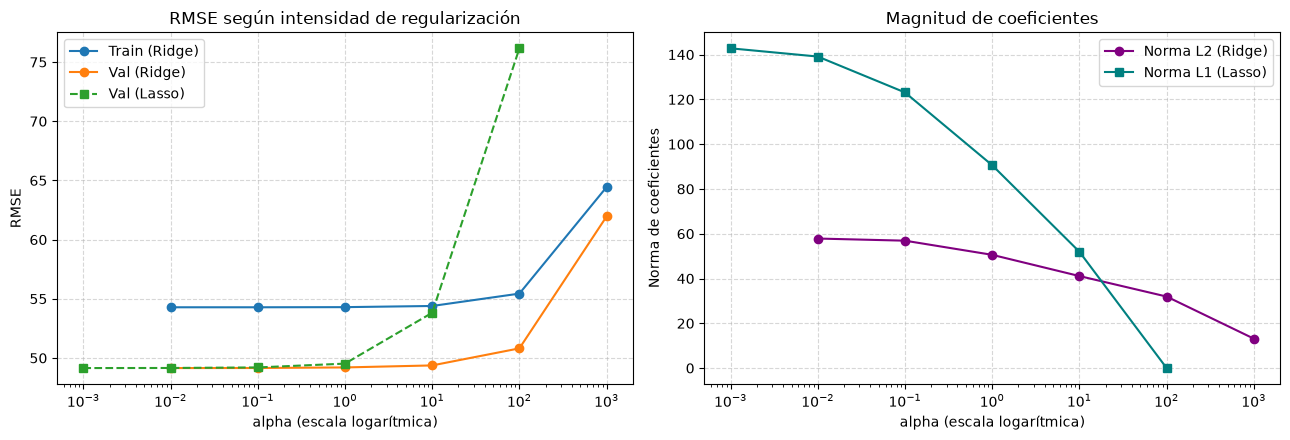

In [23]:
# 1. Ridge
alphas_ridge = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
filas_ridge = []
for a in alphas_ridge:
    p = Pipeline([("scaler", StandardScaler()), ("reg", Ridge(alpha=a, random_state=42))])
    p.fit(X_reg_train, y_reg_train)
    coefs = p.named_steps["reg"].coef_
    filas_ridge.append({
        "alpha": a,
        "Norma L2 coeficientes": np.linalg.norm(coefs),
        "RMSE entrenamiento": root_mean_squared_error(y_reg_train, p.predict(X_reg_train)),
        "RMSE validación": root_mean_squared_error(y_reg_val, p.predict(X_reg_val))
    })
df_ridge = pd.DataFrame(filas_ridge)
print("Efecto de la regularización en Ridge:")
display(df_ridge.round(3))

# 2. Lasso
alphas_lasso = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
filas_lasso = []
for a in alphas_lasso:
    p = Pipeline([("scaler", StandardScaler()), ("reg", Lasso(alpha=a, random_state=42))])
    p.fit(X_reg_train, y_reg_train)
    coefs = p.named_steps["reg"].coef_
    filas_lasso.append({
        "alpha": a,
        "Coeficientes en cero": int(np.sum(coefs == 0)),
        "Norma L1 coeficientes": np.sum(np.abs(coefs)),
        "RMSE entrenamiento": root_mean_squared_error(y_reg_train, p.predict(X_reg_train)),
        "RMSE validación": root_mean_squared_error(y_reg_val, p.predict(X_reg_val))
    })
df_lasso = pd.DataFrame(filas_lasso)
print("\nEfecto de la regularización en Lasso:")
display(df_lasso.round(3))

# Gráficos de curvas de error y coeficientes
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(df_ridge["alpha"], df_ridge["RMSE entrenamiento"], marker="o", label="Train (Ridge)")
axes[0].plot(df_ridge["alpha"], df_ridge["RMSE validación"], marker="o", label="Val (Ridge)")
axes[0].plot(df_lasso["alpha"], df_lasso["RMSE validación"], marker="s", linestyle="--", label="Val (Lasso)")
axes[0].set_xscale("log")
axes[0].set_title("RMSE según intensidad de regularización")
axes[0].set_xlabel("alpha (escala logarítmica)")
axes[0].set_ylabel("RMSE")
axes[0].grid(linestyle="--", alpha=0.5)
axes[0].legend()

axes[1].plot(df_ridge["alpha"], df_ridge["Norma L2 coeficientes"], marker="o", color="purple", label="Norma L2 (Ridge)")
axes[1].plot(df_lasso["alpha"], df_lasso["Norma L1 coeficientes"], marker="s", color="teal", label="Norma L1 (Lasso)")
axes[1].set_xscale("log")
axes[1].set_title("Magnitud de coeficientes")
axes[1].set_xlabel("alpha (escala logarítmica)")
axes[1].set_ylabel("Norma de coeficientes")
axes[1].grid(linestyle="--", alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()


## Resultados

### Paso 6. Evaluación final en prueba

Con las configuraciones ya congeladas, reentrené cada modelo utilizando los datos de desarrollo (entrenamiento + validación, 353 pacientes) y evalué su desempeño sobre los 89 pacientes de prueba.

También incluí la referencia constante (`DummyRegressor`), que predice la media de desarrollo para todos los pacientes.


,Modelo,Configuración seleccionada,RMSE validación,MAE prueba,RMSE prueba,R2 prueba
0,Regresión lineal,valores por defecto,49.150,46.677,56.648,0.445
1,Ridge,alpha=0.01,49.150,46.677,56.649,0.445
2,Lasso,alpha=0.001,49.150,46.678,56.649,0.445
3,kNN,"n_neighbors=11, weights=distance",54.181,45.472,56.949,0.439
4,Árbol de regresión,"max_depth=3, min_samples_leaf=15",55.738,49.215,62.710,0.320
5,Random Forest,"max_depth=3, min_samples_leaf=5, n_estimators=200",51.771,45.251,55.486,0.468
6,Gradient Boosting,"learning_rate=0.1, max_depth=1, n_estimators=100",50.213,45.534,55.403,0.469
7,MLP,"alpha=0.1, hidden_layer_sizes=(8,)",50.304,45.845,55.460,0.468
8,Media de desarrollo (Referencia),strategy='mean',NaN,66.823,77.140,-0.029


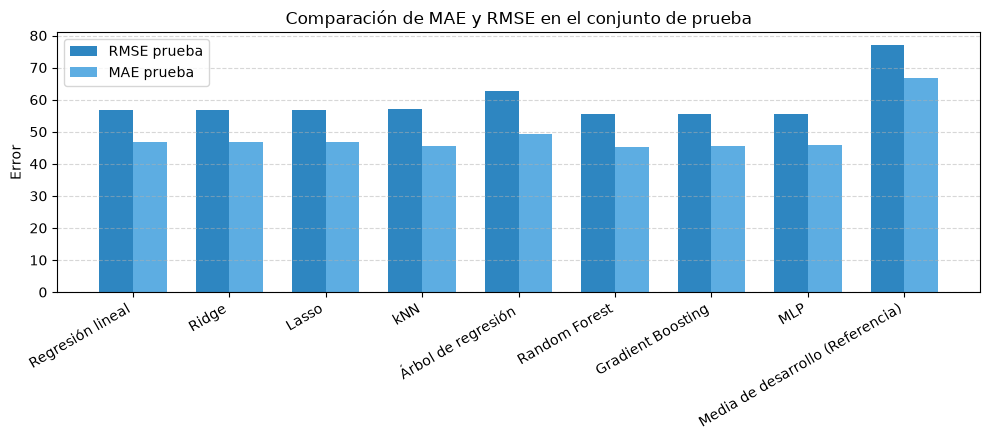

In [24]:
from sklearn.dummy import DummyRegressor

# Conjunto de desarrollo (Train + Val)
X_reg_dev = pd.concat([X_reg_train, X_reg_val])
y_reg_dev = pd.concat([y_reg_train, y_reg_val])

modelos_finales = {}
predicciones_test = {}
filas_test = []

for nombre, d in mejores_regresores.items():
    mod_final = clone(d["modelo"])
    mod_final.fit(X_reg_dev, y_reg_dev)
    pred_test = mod_final.predict(X_reg_test)
    modelos_finales[nombre] = mod_final
    predicciones_test[nombre] = pred_test
    m = evaluar_regresion(y_reg_test, pred_test)
    filas_test.append({
        "Modelo": nombre,
        "Configuración seleccionada": formatear_params(d["params"]),
        "RMSE validación": d["RMSE_val"],
        "MAE prueba": m["MAE"],
        "RMSE prueba": m["RMSE"],
        "R2 prueba": m["R2"]
    })

# Referencia constante (media de desarrollo)
referencia = DummyRegressor(strategy="mean")
referencia.fit(X_reg_dev, y_reg_dev)
pred_ref = referencia.predict(X_reg_test)
m_ref = evaluar_regresion(y_reg_test, pred_ref)
filas_test.append({
    "Modelo": "Media de desarrollo (Referencia)",
    "Configuración seleccionada": "strategy='mean'",
    "RMSE validación": np.nan,
    "MAE prueba": m_ref["MAE"],
    "RMSE prueba": m_ref["RMSE"],
    "R2 prueba": m_ref["R2"]
})

resultados_test = pd.DataFrame(filas_test)
display(resultados_test.round(3))

# Gráfico comparativo de métricas en prueba
fig, ax = plt.subplots(figsize=(10, 4.5))
x_pos = np.arange(len(resultados_test))
ancho = 0.35
ax.bar(x_pos - ancho/2, resultados_test["RMSE prueba"], width=ancho, label="RMSE prueba", color="#2e86c1")
ax.bar(x_pos + ancho/2, resultados_test["MAE prueba"], width=ancho, label="MAE prueba", color="#5dade2")
ax.set_xticks(x_pos)
ax.set_xticklabels(resultados_test["Modelo"], rotation=30, ha="right")
ax.set_title("Comparación de MAE y RMSE en el conjunto de prueba")
ax.set_ylabel("Error")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()


### Gráficos de diagnóstico y errores grandes (Regresión Lineal vs MLP)

Para examinar en detalle la calidad de ajuste en prueba:
1. **Valores reales vs predicciones:** Muestra la cercanía de los puntos a la diagonal de predicción exacta.
2. **Gráfico de residuos:** Muestra la diferencia ($y_{\text{real}} - y_{\text{pred}}$) frente a las predicciones.
3. **Análisis de dos pacientes con errores grandes:** Identificamos los pacientes de prueba con mayor error absoluto en ambos modelos y analizamos sus variables clínicas.


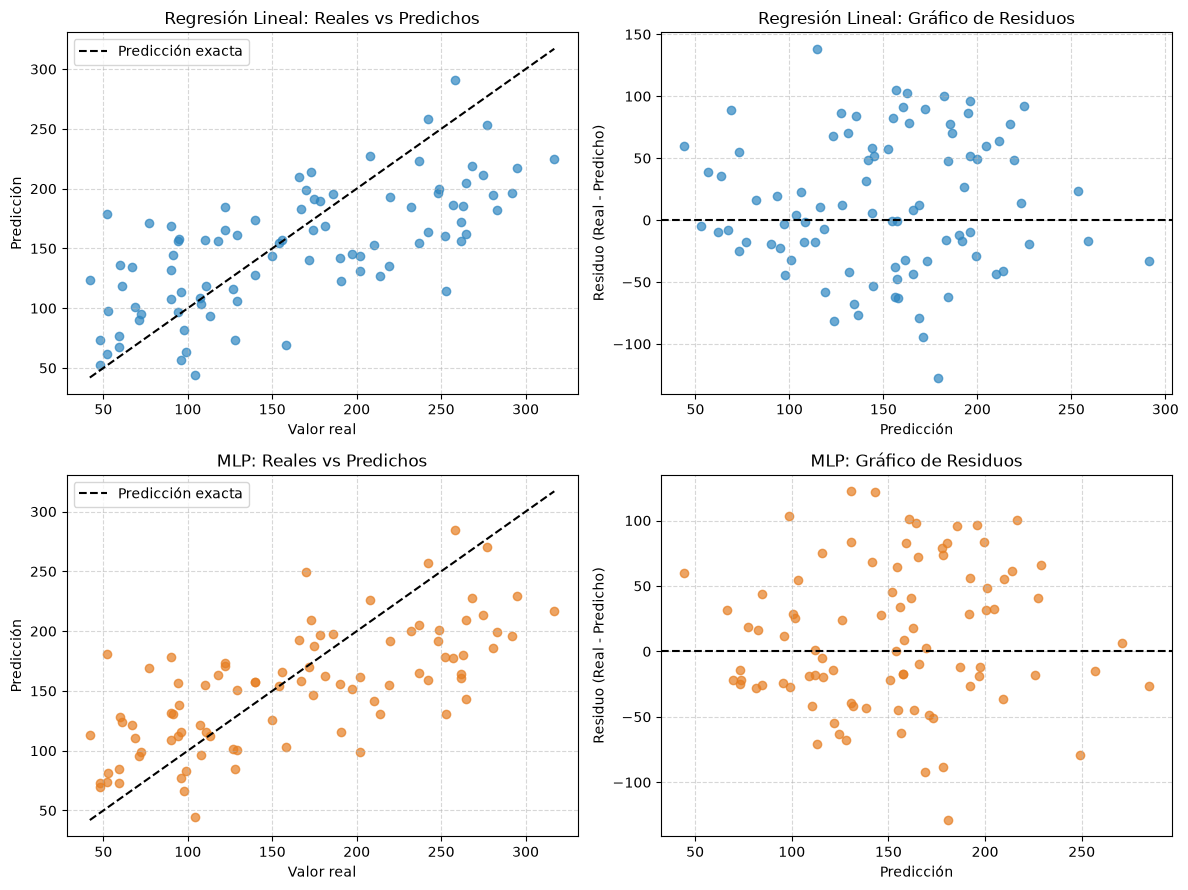

Dos pacientes con mayores errores absolutos en prueba:


,Índice paciente,Valor real,Predicción Lineal,Residuo Lineal,Predicción MLP,Residuo MLP
0,304,253.0,114.69,138.31,130.65,122.35
1,380,52.0,179.14,-127.14,180.88,-128.88



Características clínicas de los pacientes 304 y 380 frente al promedio:


,304,380,Promedio desarrollo
age,60.00,53.00,48.68
sex,2.00,1.00,1.46
bmi,22.80,28.80,26.35
bp,110.00,111.67,94.54
s1,245.00,145.00,188.91
s2,189.80,87.20,115.14
s3,39.00,46.00,49.79
s4,6.00,3.15,4.07
s5,4.39,4.08,4.64
s6,88.00,85.00,91.23


In [25]:
# Predicciones y residuos
pred_lin = predicciones_test["Regresión lineal"]
res_lin = y_reg_test.to_numpy() - pred_lin

pred_mlp = predicciones_test["MLP"]
res_mlp = y_reg_test.to_numpy() - pred_mlp

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Reales vs Predichos Lineal
axes[0, 0].scatter(y_reg_test, pred_lin, alpha=0.7, color="#2e86c1")
lims_lin = [min(y_reg_test.min(), pred_lin.min()), max(y_reg_test.max(), pred_lin.max())]
axes[0, 0].plot(lims_lin, lims_lin, "--", color="black", label="Predicción exacta")
axes[0, 0].set_title("Regresión Lineal: Reales vs Predichos")
axes[0, 0].set_xlabel("Valor real")
axes[0, 0].set_ylabel("Predicción")
axes[0, 0].legend()
axes[0, 0].grid(linestyle="--", alpha=0.5)

# 2. Residuos Lineal
axes[0, 1].scatter(pred_lin, res_lin, alpha=0.7, color="#2e86c1")
axes[0, 1].axhline(0, linestyle="--", color="black")
axes[0, 1].set_title("Regresión Lineal: Gráfico de Residuos")
axes[0, 1].set_xlabel("Predicción")
axes[0, 1].set_ylabel("Residuo (Real - Predicho)")
axes[0, 1].grid(linestyle="--", alpha=0.5)

# 3. Reales vs Predichos MLP
axes[1, 0].scatter(y_reg_test, pred_mlp, alpha=0.7, color="#e67e22")
lims_mlp = [min(y_reg_test.min(), pred_mlp.min()), max(y_reg_test.max(), pred_mlp.max())]
axes[1, 0].plot(lims_mlp, lims_mlp, "--", color="black", label="Predicción exacta")
axes[1, 0].set_title("MLP: Reales vs Predichos")
axes[1, 0].set_xlabel("Valor real")
axes[1, 0].set_ylabel("Predicción")
axes[1, 0].legend()
axes[1, 0].grid(linestyle="--", alpha=0.5)

# 4. Residuos MLP
axes[1, 1].scatter(pred_mlp, res_mlp, alpha=0.7, color="#e67e22")
axes[1, 1].axhline(0, linestyle="--", color="black")
axes[1, 1].set_title("MLP: Gráfico de Residuos")
axes[1, 1].set_xlabel("Predicción")
axes[1, 1].set_ylabel("Residuo (Real - Predicho)")
axes[1, 1].grid(linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Pacientes con mayores errores absolutos
idx_peores_lin = np.argsort(np.abs(res_lin))[-2:][::-1]
pacientes_seleccionados = X_reg_test.index[idx_peores_lin].tolist()

tabla_peores = pd.DataFrame({
    "Índice paciente": pacientes_seleccionados,
    "Valor real": y_reg_test.iloc[idx_peores_lin].values,
    "Predicción Lineal": pred_lin[idx_peores_lin],
    "Residuo Lineal": res_lin[idx_peores_lin],
    "Predicción MLP": pred_mlp[idx_peores_lin],
    "Residuo MLP": res_mlp[idx_peores_lin]
})
print("Dos pacientes con mayores errores absolutos en prueba:")
display(tabla_peores.round(2))

print("\nCaracterísticas clínicas de los pacientes 304 y 380 frente al promedio:")
media_dev = X_reg_dev.mean().to_frame(name="Promedio desarrollo")
comparacion_pacientes = pd.concat([X_reg_test.loc[pacientes_seleccionados].T, media_dev], axis=1)
display(comparacion_pacientes.round(2))


## Interpretación

### 1. ¿Qué modelo tuvo el mejor desempeño?
- Si evaluamos con **RMSE** el mejor modelo fue **Gradient Boosting**, que alcanzó el menor error con **55.403** y el mayor coeficiente de determinación con $R^2 = \mathbf{0.469}$, seguido muy de cerca por el **MLP** (RMSE = 55.460) y **Random Forest** (RMSE = 55.486).
- Si evaluamos con **MAE**, el primer lugar fue para **Random Forest**, con un error absoluto medio de **45.251**, superando a Gradient Boosting (45.534).
- Por lo tanto, el "ganador" depende de la métrica considerada: Gradient Boosting minimizó mejor los errores grandes, mientras que Random Forest tuvo un menor error absoluto promedio. Todos los regresores superaron ampliamente a la referencia constante (`DummyRegressor`), cuyo RMSE fue de 77.140 y MAE de 66.823.

### 2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
- **MAE** promedia directamente las magnitudes de los errores absolutos sin importar si son grandes o pequeños.
- **RMSE** eleva al cuadrado cada error antes de promediar y sacar la raíz, por lo que castiga de forma mucho más severa a las predicciones que se alejan demasiado de la realidad.

### 3. ¿Cómo se interpreta un $R^2$ negativo?
- Un $R^2$ negativo significa que el modelo genera un error cuadrático mayor que el que se obtendría simplemente prediciendo el valor promedio de la variable respuesta para todas las observaciones. No significa que el error sea negativo ni que exista una correlación inversa.

### 4. ¿Qué efecto tuvo aumentar la regularización?
- En **Ridge (L2)**, al incrementar `alpha` de 0.01 a 1000, la norma de los coeficientes se comprimió drásticamente (pasó de 57.85 a 13.13), pero el RMSE de validación empeoró de 49.15 a 61.96 debido a un subajuste severo.
- En **Lasso (L1)**, al aumentar `alpha` de 0.001 a 100, la penalización forzó coeficientes a cero progresivamente (con `alpha=1` anuló 2 coeficientes, con `alpha=10` anuló 6 y con `alpha=100` anuló los 10), provocando que el RMSE de validación subiera de 49.15 a 76.16 (quedando equivalente a predecir una constante).
- En esta partición, aumentar fuertemente la regularización no mejoró el resultado sino que quitó capacidad predictiva; por eso la validación seleccionó las intensidades más bajas (`alpha=0.01` en Ridge y `alpha=0.001` en Lasso), donde los modelos se comportaron de forma casi idéntica a la regresión lineal estándar.

### 5. ¿Qué puede explicar los errores grandes?
- Al analizar los pacientes **304** y **380**, ambos modelos (Regresión Lineal y MLP) cometieron sus peores predicciones en los mismos casos:
  - En el paciente **304**, el valor real fue 253 y los modelos predijeron ~115–130 (se quedaron muy cortos por más de 120 unidades).
  - En el paciente **380**, el valor real fue 52 y los modelos predijeron ~179–181 (sobreestimaron por más de 127 unidades).

### 6. ¿Un coeficiente predictivo demuestra una relación causal?
- No, un coeficiente en un modelo de regresión únicamente cuantifica la asociación estadística entre una característica y la variable de respuesta dentro del contexto del modelo, manteniendo las demás variables constantes.
- No demuestra causalidad porque puede existir confusión por variables no observadas, correlaciones indirectas entre sesgos de muestreo. Modificar artificialmente una de las variables (como intentar bajar la presión con un medicamento) no garantiza que la progresión de la diabetes vaya a cambiar exactamente en la magnitud del coeficiente estimado. Para establecer causalidad se requeriría un ensayo clínico controlado o un diseño causal formal.
